![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# METRIC: Internal Calibration against Reference ET

METRIC, Mapping EvapoTranspiration at high Resolution with Internalized Calibration (Allen et al.
2007), keeps SEBAL's machinery and changes its two weakest assumptions. Instead of assuming that
the cold anchor has no sensible heat, it sets the cold anchor's ET to that of a well watered
alfalfa reference computed from weather, which lets irrigated fields evaporate more than their net
radiation when hot, dry air flows over them. Instead of scaling the image to a day with net
radiation, it scales with the same reference: the fraction of reference ET (ETrF) is assumed
constant through the day. METRIC is the basis of eeMETRIC in OpenET and of many state water
agencies' ET programmes in the western United States. This notebook calibrates METRIC on the 5 July
2024 scene, compares it with SEBAL, and repeats the calibration through the 2024 season.

## Overview

### What METRIC changes

| Step | SEBAL | METRIC |
|---|---|---|
| Cold anchor | `H = 0`, `LE = Rn - G` | `ET = 1.05 ETr`, `H = Rn - G - 1.05 ETr lambda` (can be negative) |
| Hot anchor | `LE = 0` | `ET = ETrF_hot ETr`, with `ETrF_hot` from a daily soil water balance of bare soil (FAO-56 evaporation); 0 after a long dry period |
| `dT` calibration | on `Ts` | on `Ts_datum`, LST moved to a common elevation with a lapse rate (mountain scenes) |
| Incoming shortwave | flat ground | slope and aspect of every pixel |
| Daily ET | `EF Rn24` | `ETrF ETr24` |
| Monthly and seasonal ET | | ETrF interpolated between images, times daily ETr (notebook 10) |

### Why 1.05 ETr at the cold anchor

The alfalfa reference represents a tall, dense, well watered crop. Allen et al. (2007) found that
the coolest, fully vegetated fields in an agricultural scene typically evaporate about 5 % more
than the reference, because they are slightly rougher, wetter or warmer-surrounded than a
reference field. More recent METRIC applications often use 1.0 for the cold anchor and account for
the extra 5 % elsewhere; the value is a parameter (`etrf_cold`).

### Why the reference ET fraction carries the day

`EF` is constant through a day only if the energy partition does not change. In advective regions
the afternoon brings hotter, drier air, so ET rises relative to `Rn - G` and EF increases during
the day. ETrF holds better, because the alfalfa reference responds to the same advection. Allen
et al. (2007) and many studies since found ETrF from a late morning image to be a good estimate of
the 24 hour ratio for irrigated crops.

### The hot anchor after rain

A bare field that was wetted by rain in the last days still evaporates. METRIC runs the FAO-56 soil
evaporation model (a two stage water balance of the top 10 cm) with daily rain and reference ET to
estimate `ETrF_hot`. In the dry San Joaquin summer the last rain is months back and
`ETrF_hot = 0`.

## METRIC with GeoLattice

| Function | Purpose |
|---|---|
| `seb.run_metric(lst, rn, g, zom, u200, pressure, etr_inst, anchors=, etrf_cold=, etrf_hot=, etr_daily=, lst_dt=)` | METRIC: `H`, `LE`, instantaneous ET, ETrF and daily ET |
| `seb.asce_pm_hourly`, `seb.asce_pm_daily` | alfalfa reference ET at the overpass and for the day (notebook 02) |
| `seb.datum_temperature` | LST moved to a common elevation |
| `seb.calibration_history`, `seb.anchor_report` | the calibration record |
| `sd.run_metric_scene` | METRIC with the chapter defaults for any cached scene |

### Learning objectives

1. Explain the two METRIC changes to SEBAL and why they matter in advective climates.
2. Calibrate METRIC with hourly alfalfa reference ET and inspect the calibration.
3. Map ETrF and daily ET, and read ETrF as a satellite crop coefficient.
4. Compare METRIC and SEBAL on the same scene and explain the differences.
5. Estimate the hot anchor's ETrF from recent rain.
6. Calibrate METRIC through a season and follow how the calibration changes.

### Data

The 5 July 2024 Landsat 8 scene and five more 2024 scenes of the Westside San Joaquin Valley
(`sd.load_scene`), the inputs of notebooks 03 and 04 (`sd.energy_inputs`), and hourly and daily
ERA5 weather for reference ET.

### Contents

- Setup
- Reference ET and the hot anchor
- Calibrating METRIC
- Sensible heat below zero
- ETrF and daily ET
- METRIC and SEBAL
- The datum temperature
- A season of calibrations
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

ds = sd.load_scene()  # Landsat 8, 5 July 2024
p = sd.energy_inputs(ds)  # radiation, soil heat flux, roughness, anchors, reference ET
ext = [float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())]  # map extent
GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217], "Grapes": [69], "Annual crops": [54, 2, 1, 36, 208, 24, 21, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152], "Developed": [121, 122, 123, 124]}  # CDL codes per group


def by_group(**layers):  # mean of each layer per crop group
    df = xr.Dataset(layers).assign(cdl=ds.cdl).to_dataframe().dropna()  # one row per pixel
    return pd.DataFrame({g: df[df.cdl.isin(c)].drop(columns=["cdl", "spatial_ref"], errors="ignore").mean()
                         for g, c in GROUPS.items()}).T  # group means

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## Reference ET and the hot anchor

`sd.energy_inputs` already computed the alfalfa reference ET at the overpass and for the day from
ERA5 (notebook 02). The hot anchor's ETrF depends on how long ago it last rained.

In [2]:
print(f"ETr at the overpass {p['etr_inst']:.3f} mm/h | ETr for the day {p['etr_daily']:.2f} mm | ETo for the day {p['eto_daily']:.2f} mm")  # reference ET
rain = sd.weather(sd.WESTSIDE, "2024-01-01", "2024-12-31")["daily"]["precipitation_sum"]  # ERA5 daily rain
wet = rain[(rain.index < "2024-07-05") & (rain > 2)]  # days with more than 2 mm before the image
print(f"last day with more than 2 mm of rain: {wet.index.max():%d %B %Y} ({(pd.Timestamp('2024-07-05') - wet.index.max()).days} days before the image)")  # dry spell
print(f"rain in the 30 days before the image: {rain.loc['2024-06-05':'2024-07-04'].sum():.1f} mm")  # recent rain

ETr at the overpass 0.931 mm/h | ETr for the day 15.61 mm | ETo for the day 10.70 mm
last day with more than 2 mm of rain: 05 May 2024 (61 days before the image)
rain in the 30 days before the image: 0.0 mm


After two months without rain the top soil of a bare field is dry and the FAO-56 evaporation model
gives `ETrF_hot` of zero, so the hot anchor is treated as in SEBAL.

## Calibrating METRIC

The cold anchor must evaporate `1.05 ETr`, the hot anchor nothing. Converting the instantaneous ETr
to a latent heat flux gives the energy each anchor uses.

In [3]:
anchors = p["anchors"]  # the automated anchors of notebook 05
cy, cx, hy, hx = anchors["cold"]["iy"], anchors["cold"]["ix"], anchors["hot"]["iy"], anchors["hot"]["ix"]  # rows and columns
lam = float(seb.latent_heat_of_vaporization(anchors["cold"]["lst"]))  # J/kg at the cold anchor
le_cold = 1.05 * p["etr_inst"] * lam / 3600  # W/m2
avail_cold = float(p["rn"][cy, cx] - p["g"][cy, cx])  # Rn - G at the cold anchor
print(f"cold anchor: Rn - G = {avail_cold:.0f} W/m2, LE = 1.05 ETr = {le_cold:.0f} W/m2, so H = {avail_cold - le_cold:.0f} W/m2")  # cold anchor energy
res = seb.run_metric(p["lst"], p["rn"], p["g"], p["zom"], p["u200"], p["pressure"], p["etr_inst"],
                     anchors=anchors, etrf_cold=1.05, etrf_hot=0.0, etr_daily=p["etr_daily"])  # METRIC
hist = seb.calibration_history(res)  # iterations
print(f"converged after {res.attrs['iterations']} iterations: dT = {res.attrs['a']:.2f} + {res.attrs['b']:.4f} Ts")  # calibration
hist.round(3)  # the iterations

cold anchor: Rn - G = 605 W/m2, LE = 1.05 ETr = 657 W/m2, so H = -52 W/m2


converged after 5 iterations: dT = -136.57 + 0.4258 Ts


,rah_hot,rah_cold,u_star_hot,dt_hot,dt_cold,a,b,h_hot,L_hot
iteration,,,,,,,,,
1,60.502,42.958,0.121,18.005,-1.984,-250.533,0.806,328.931,-0.490
2,13.170,69.338,0.150,3.900,-3.204,-91.534,0.286,313.282,-0.945
3,17.455,86.884,0.150,5.400,-4.030,-121.291,0.380,328.800,-0.905
4,17.144,100.778,0.150,5.280,-4.687,-128.618,0.402,327.182,-0.909
5,17.176,113.035,0.150,5.291,-5.268,-136.572,0.426,327.314,-0.909


The cold anchor uses more energy for evaporation than its `Rn - G`: under the hot, dry air of this
heat wave, 1.05 x 0.93 mm/h needs 657 W m-2 against 605 W m-2 of `Rn - G`, so the anchor must draw
about 52 W m-2 of heat from the air (negative `H`). Its `dT` is negative, the air is warmer than the surface, and the stable air above
it raises its `rah`. The calibration line is steeper than SEBAL's, because it now spans from a
negative `dT` at the cold end to the hot anchor's `dT`.

## Sensible heat below zero

pixels with H < 0: 37.2%


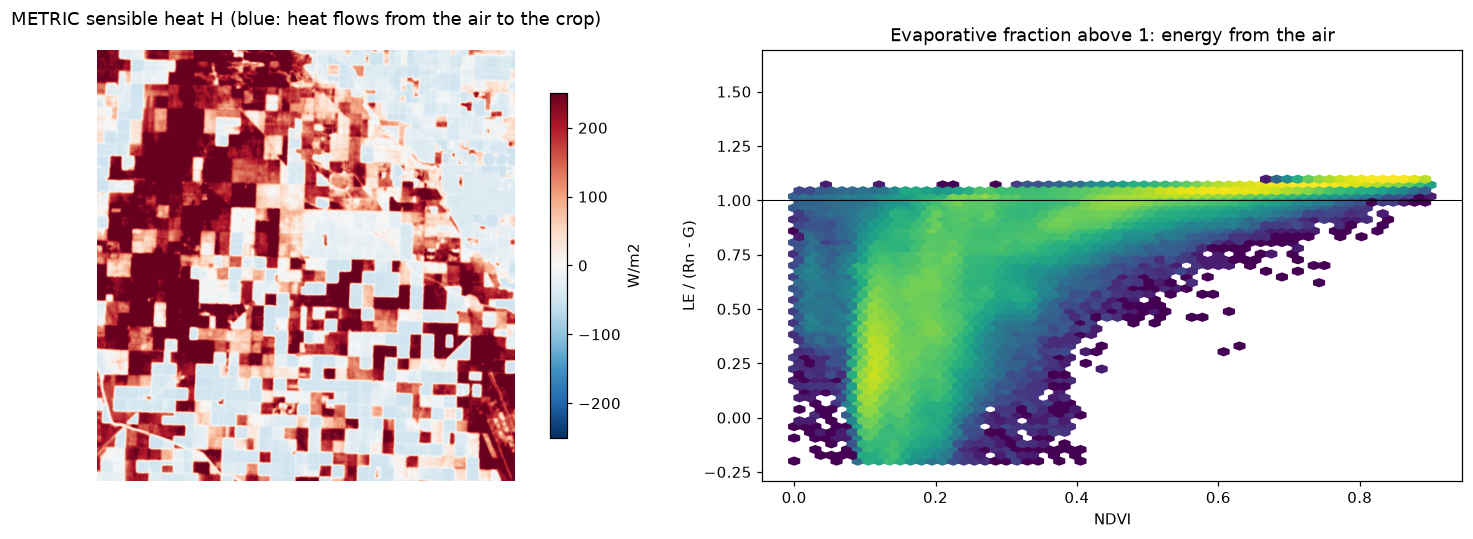

In [4]:
neg = float((res.h < 0).sum() / res.h.notnull().sum())  # share of pixels with H < 0
print(f"pixels with H < 0: {neg:.1%}")  # advection
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # two maps
im = ax[0].imshow(res.h, extent=ext, cmap="RdBu_r", vmin=-250, vmax=250); plt.colorbar(im, ax=ax[0], shrink=0.8, label="W/m2")  # H map
ax[0].set_title("METRIC sensible heat H (blue: heat flows from the air to the crop)"); ax[0].axis("off")  # title
lam_map = seb.latent_heat_of_vaporization(p["lst"])  # J/kg
ratio = res.le / (p["rn"] - p["g"])  # LE / (Rn - G), the evaporative fraction without clipping
ax[1].hexbin(p["ndvi"].values.ravel(), ratio.values.ravel(), gridsize=60, bins="log", extent=(0, 0.9, -0.2, 1.6))  # EF vs NDVI
ax[1].axhline(1, color="k", lw=0.7); ax[1].set_xlabel("NDVI"); ax[1].set_ylabel("LE / (Rn - G)")  # labels
ax[1].set_title("Evaporative fraction above 1: energy from the air"); plt.tight_layout(); plt.show()  # draw

37 % of the pixels have negative `H`, and many vegetated fields have `LE > Rn - G`. This is what makes METRIC suited to irrigated land in
arid climates: SEBAL's cold anchor rule caps every field at `LE = Rn - G`.

## ETrF and daily ET

ETrF is the satellite equivalent of a crop coefficient relative to alfalfa. `seb.run_metric`
clips it to 0 to 1.3 before multiplying by the daily reference ET.

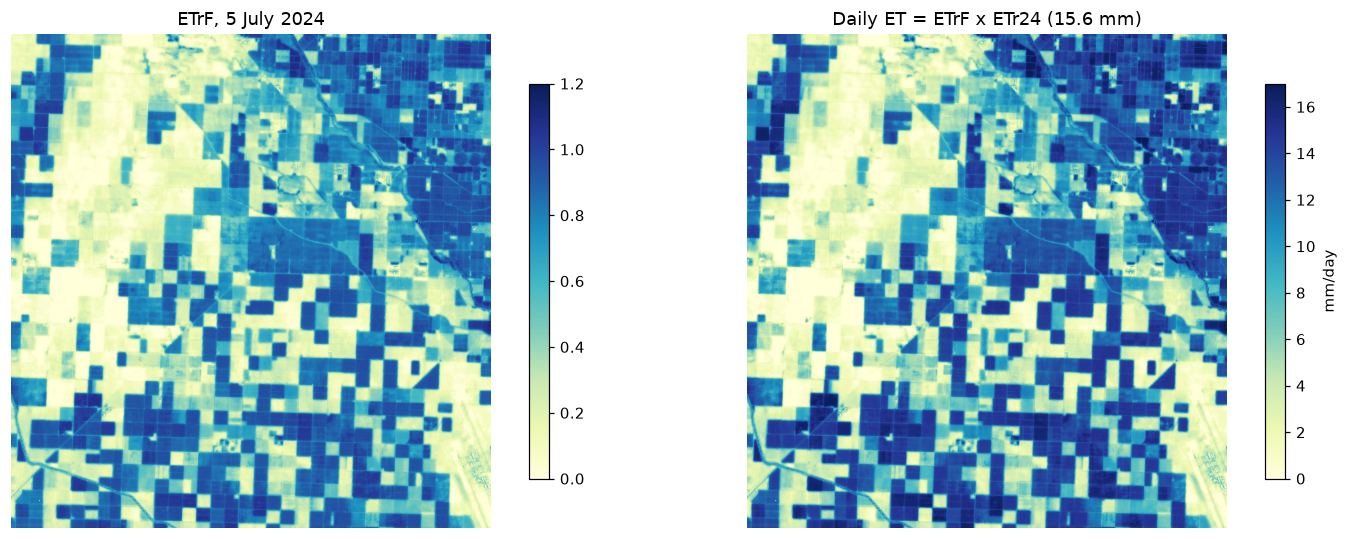

,pixels,ETrF median,ETrF p90,daily ET (mm)
Tomatoes,79364.0,0.92,0.95,14.35
Almonds,81227.0,0.90,1.02,14.12
Cotton,41084.0,0.86,0.97,13.44
Grapes,55411.0,0.84,0.94,13.07
Pistachios,162036.0,0.71,0.89,11.14
Chickpeas,16702.0,0.44,0.60,6.88
Garlic,18961.0,0.41,0.53,6.42
"Developed, low intensity",18668.0,0.39,0.74,6.15
"Developed, open space",17141.0,0.38,0.74,5.94
Grassland/pasture,49785.0,0.23,0.55,3.57


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # two maps
im = ax[0].imshow(res.etrf, extent=ext, cmap="YlGnBu", vmin=0, vmax=1.2); plt.colorbar(im, ax=ax[0], shrink=0.8)  # ETrF
ax[0].set_title("ETrF, 5 July 2024"); ax[0].axis("off")  # title
im = ax[1].imshow(res.et24, extent=ext, cmap="YlGnBu", vmin=0, vmax=17); plt.colorbar(im, ax=ax[1], shrink=0.8, label="mm/day")  # daily ET
ax[1].set_title(f"Daily ET = ETrF x ETr24 ({p['etr_daily']:.1f} mm)"); ax[1].axis("off")  # title
plt.tight_layout(); plt.show()  # draw
crops = ds.cdl.where(p["mask"]).to_series().value_counts().index[:12]  # the 12 most common classes
tab = pd.DataFrame({sd.cdl_name(c): {"pixels": int((ds.cdl == c).sum()), "ETrF median": float(res.etrf.where(ds.cdl == c).median()),
                                      "ETrF p90": float(res.etrf.where(ds.cdl == c).quantile(0.9)),
                                      "daily ET (mm)": float(res.et24.where(ds.cdl == c).median())} for c in crops}).T  # per crop class
tab.sort_values("ETrF median", ascending=False).round(2)  # table

The table reads like a list of crop coefficients for early July: well watered, near full-cover
crops have ETrF close to 1, orchards somewhat less (they do not cover the ground fully, and many
growers deficit-irrigate pistachios and almonds in summer), and fallow land close to zero. The 90th
percentile shows the best watered fields of each crop.

## METRIC and SEBAL

Both models were run on the same inputs and anchors. The difference comes from the two METRIC
changes.

,LE_sebal,LE_metric,ET24_sebal,ET24_metric,ratio
Tree crops,337.38,424.81,4.85,10.73,2.21
Grapes,402.64,499.43,5.43,12.57,2.32
Annual crops,304.85,387.73,4.12,9.78,2.37
Fallow,62.18,103.79,1.27,2.72,2.14
Grass and shrubs,94.32,156.77,1.82,4.12,2.26
Developed,163.81,244.98,2.84,6.24,2.20


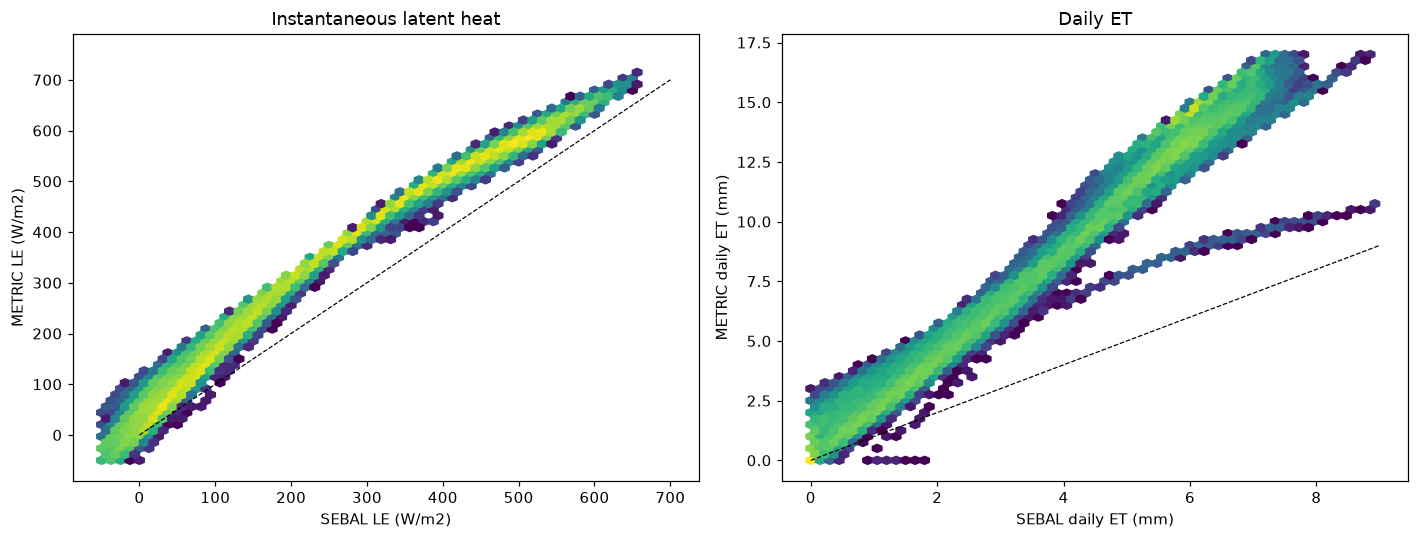

In [6]:
rs24 = ds.attrs["rs_daily_mj"] * 1e6 / 86400  # W/m2
ra24 = float(seb.extraterrestrial_radiation_daily(sd.WESTSIDE["lat"], ds.attrs["doy"])) * 1e6 / 86400  # W/m2
sebal = seb.run_sebal(p["lst"], p["rn"], p["g"], p["zom"], p["u200"], p["pressure"], anchors=anchors,
                      rn24=seb.daily_net_radiation(rs24, p["albedo"], ra24=ra24))  # SEBAL with the same inputs
comp = by_group(LE_sebal=sebal.le, LE_metric=res.le, ET24_sebal=sebal.et24, ET24_metric=res.et24)  # per crop group
comp["ratio"] = comp.ET24_metric / comp.ET24_sebal  # METRIC / SEBAL
display(comp.round(2))  # table
sebal_etrf_inst = sebal.et_inst / p["etr_inst"]  # SEBAL's instantaneous ETrF
fig, ax = plt.subplots(1, 2, figsize=(13, 5))  # two panels
ax[0].hexbin(sebal.le.values.ravel(), res.le.values.ravel(), gridsize=60, bins="log", extent=(-50, 700, -50, 750)); ax[0].plot([0, 700], [0, 700], "k--", lw=0.8)  # instantaneous LE
ax[0].set_xlabel("SEBAL LE (W/m2)"); ax[0].set_ylabel("METRIC LE (W/m2)"); ax[0].set_title("Instantaneous latent heat")  # labels
ax[1].hexbin(sebal.et24.values.ravel(), res.et24.values.ravel(), gridsize=60, bins="log", extent=(0, 9, 0, 17)); ax[1].plot([0, 9], [0, 9], "k--", lw=0.8)  # daily ET
ax[1].set_xlabel("SEBAL daily ET (mm)"); ax[1].set_ylabel("METRIC daily ET (mm)"); ax[1].set_title("Daily ET")  # labels
plt.tight_layout(); plt.show()  # draw

At the overpass the two models differ moderately: METRIC's LE is 80 to 100 W m-2 higher over the
crops (its cold anchor takes heat from the air) and about 40 W m-2 higher over fallow land, where
both models are tied to the same hot anchor. Daily ET
differs much more. SEBAL scales by the 24 hour net radiation, about 195 W m-2 here, while METRIC
scales by the 24 hour alfalfa reference ET of 15.6 mm, which corresponds to some 440 W m-2 of
evaporation. On a heat wave day with strong advection the reference captures the extra energy the
air delivers in the afternoon; net radiation does not. This is why scaling with reference ET is
preferred for irrigated crops in arid regions, and why eeMETRIC rather than an EF-based daily
scaling is part of OpenET. Notebook 11 compares the models with independent estimates.

## The datum temperature

In mountainous scenes, air cools with elevation, and a high field looks cold because it is high,
not because it evaporates. METRIC calibrates `dT` on LST moved to a common elevation with a lapse
rate (6.5 K per km). The Westside floor spans only about 100 m, so the effect here is small, but
the code is the same anywhere.

In [7]:
lst_datum = seb.datum_temperature(p["lst"], ds.dem)  # LST at the median elevation
res_d = seb.run_metric(p["lst"], p["rn"], p["g"], p["zom"], p["u200"], p["pressure"], p["etr_inst"],
                       anchors=anchors, etr_daily=p["etr_daily"], lst_dt=lst_datum)  # METRIC on the datum temperature
diff = res_d.et24 - res.et24  # mm/day
print(f"datum elevation {lst_datum.attrs['z_ref']:.0f} m | LST shifted by {float((lst_datum - p['lst']).min()):+.2f} to {float((lst_datum - p['lst']).max()):+.2f} K")  # shift
print(f"daily ET change: mean {float(diff.mean()):+.3f} mm, 99th percentile of |change| {float(np.abs(diff).quantile(0.99)):.3f} mm")  # effect

datum elevation 66 m | LST shifted by -0.15 to +0.48 K
daily ET change: mean -0.020 mm, 99th percentile of |change| 0.216 mm


## A season of calibrations

`sd.run_metric_scene` applies the same chain (inputs, automated anchors, reference ET, METRIC) to
any cached scene. Six dates from April to September show how the calibration changes with the
season.

,air C,ETr inst (mm/h),ETr24 (mm),cold LST (C),hot LST (C),a,b,iterations,ETrF scene median,ET24 scene mean (mm)
date,,,,,,,,,,
2024-04-08,16.5,0.566,5.562,16.426,26.363,-102.111,0.363,5,0.311,2.158
2024-05-26,25.1,0.694,8.668,28.041,50.976,-99.658,0.337,6,0.229,2.644
2024-06-19,31.5,0.805,10.908,30.710,54.571,-48.554,0.165,6,0.386,4.458
2024-07-05,39.8,0.931,15.611,35.236,60.037,-136.572,0.426,5,0.534,8.196
2024-08-14,33.6,0.695,10.821,32.809,57.145,-215.072,0.706,6,0.269,3.797
2024-09-23,32.5,0.607,7.235,33.229,53.317,-155.494,0.511,6,0.221,2.245


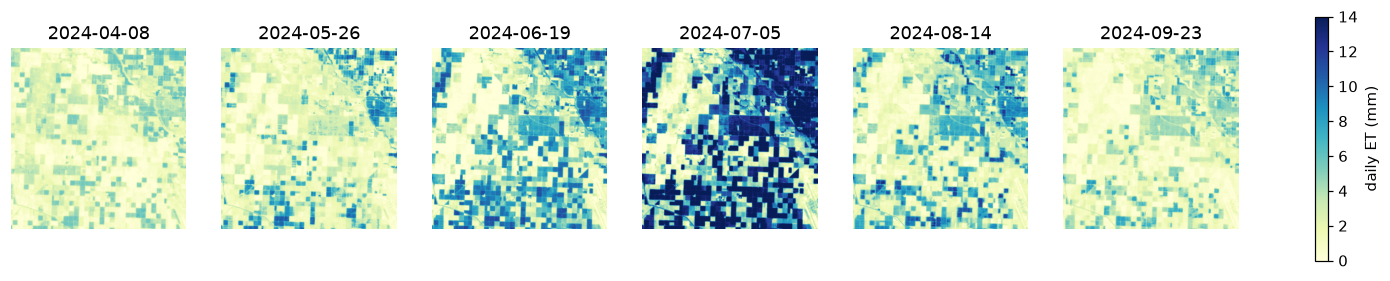

In [8]:
DATES = ["LC09_L2SP_042035_20240408_02_T1", "LC09_L2SP_042035_20240526_02_T1", "LC08_L2SP_042035_20240619_02_T1",
         "LC08_L2SP_042035_20240705_02_T1", "LC09_L2SP_042035_20240814_02_T1", "LC08_L2SP_042035_20240923_02_T1"]  # six scenes
rows, maps = [], {}  # calibration table and daily ET maps
for sid in DATES:  # every scene
    s = sd.load_scene(sid)  # cached stack
    q = sd.energy_inputs(s)  # its inputs and anchors
    r = sd.run_metric_scene(s, q)  # METRIC
    date = pd.Timestamp(s.attrs["datetime"]).date()  # image date
    maps[date] = r.et24  # keep the daily ET map
    rows.append({"date": date, "air C": round(s.attrs["t_air_c"], 1), "ETr inst (mm/h)": q["etr_inst"], "ETr24 (mm)": q["etr_daily"],
                 "cold LST (C)": q["anchors"]["cold"]["lst"] - 273.15, "hot LST (C)": q["anchors"]["hot"]["lst"] - 273.15,
                 "a": r.attrs["a"], "b": r.attrs["b"], "iterations": r.attrs["iterations"],
                 "ETrF scene median": float(r.etrf.median()), "ET24 scene mean (mm)": float(r.et24.mean())})  # one row
season = pd.DataFrame(rows).set_index("date")  # table
display(season.round(3))  # calibration through the season
fig, ax = plt.subplots(1, len(maps), figsize=(18, 3.6))  # one map per date
for a_, (d, mp) in zip(ax, maps.items()):  # every date
    im = a_.imshow(mp, cmap="YlGnBu", vmin=0, vmax=14); a_.set_title(str(d)); a_.axis("off")  # daily ET
plt.colorbar(im, ax=ax, shrink=0.8, label="daily ET (mm)"); plt.show()  # shared scale

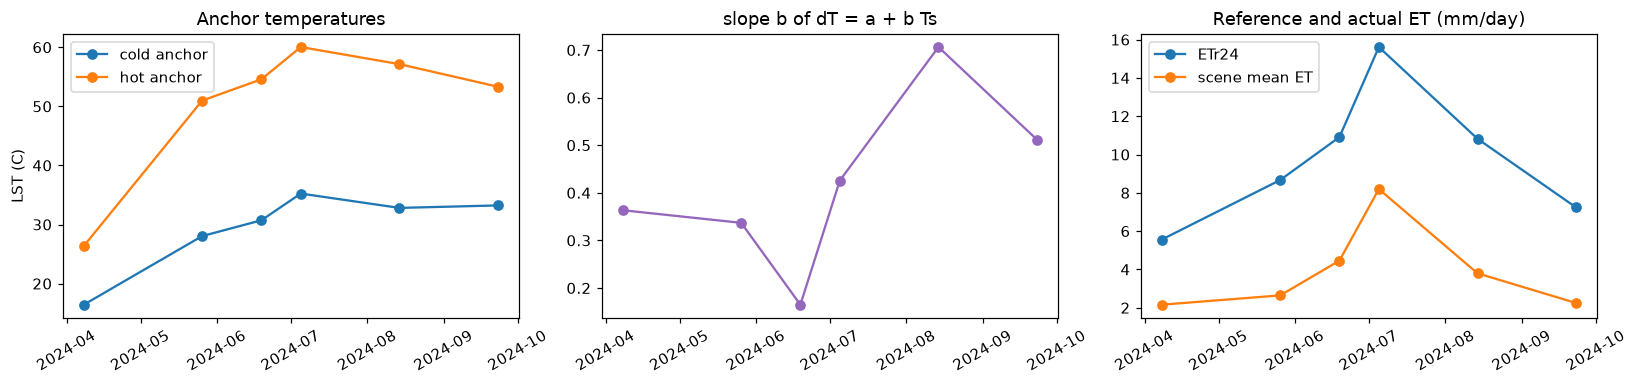

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))  # three panels
ax[0].plot(season.index, season["cold LST (C)"], "o-", label="cold anchor"); ax[0].plot(season.index, season["hot LST (C)"], "o-", label="hot anchor")  # anchor LST
ax[0].set_ylabel("LST (C)"); ax[0].legend(); ax[0].set_title("Anchor temperatures")  # labels
ax[1].plot(season.index, season.b, "o-", color="tab:purple"); ax[1].set_title("slope b of dT = a + b Ts")  # slope
ax[2].plot(season.index, season["ETr24 (mm)"], "o-", label="ETr24"); ax[2].plot(season.index, season["ET24 scene mean (mm)"], "o-", label="scene mean ET")  # reference and actual ET
ax[2].legend(); ax[2].set_title("Reference and actual ET (mm/day)")  # labels
for a_ in ax:  # every panel
    a_.tick_params(axis="x", rotation=30)  # readable dates
plt.tight_layout(); plt.show()  # draw

The calibration is redone for every image, because the anchors' temperatures, the weather and the
crops all change. On 8 April the hot anchor is only 10 K warmer than the cold anchor (26 against
16 C); from late May on the contrast is 23 to 25 K. The scene median ETrF is highest on 5 July
(0.53) and between 0.22 and 0.39 on the other dates, and the scene mean daily ET ranges from 2.2 mm
in April and September to 8.2 mm on 5 July. By mid August many annual fields (tomatoes, garlic,
wheat stubble) have been harvested and dry down while the orchards keep transpiring, so the scene
median falls even though the reference ET stays high. The slope `b` (0.17 to 0.71) is not a
physical constant but a property of each image.

The 5 July result is saved for notebooks 07 and 11.

In [10]:
res.to_netcdf(OUT / "metric_20240705.nc", encoding={v: {"zlib": True, "complevel": 4} for v in res.data_vars})  # METRIC result, compressed (history and anchors are JSON attributes)
print(OUT / "metric_20240705.nc")  # path

outputs/metric_20240705.nc


## Summary and exercises

- METRIC sets the cold anchor to `1.05 ETr` and the hot anchor to the ETrF of a soil water balance
  (zero after two months without rain), so wet fields can evaporate more than `Rn - G` by drawing
  heat from the air.
- On 5 July 2024 the cold anchor needed 657 W m-2 for evaporation, 52 W m-2 more than its
  `Rn - G`; 37 % of the pixels had negative `H`.
- ETrF reads as a crop coefficient: close to 1 for well watered full cover, lower for orchards and
  near 0 for fallow land.
- METRIC's daily ET was 2.1 to 2.4 times SEBAL's for every crop group on this advective day,
  mostly because of the daily scaling with reference ET instead of net radiation.
- The calibration changes from image to image (`b` from 0.17 to 0.71 across six dates); the datum
  temperature changed daily ET by less than 0.22 mm for 99 % of pixels on this flat valley floor.

**Exercises**

1. Rerun METRIC with `etrf_cold=1.0`. How much does daily ET change, and is the change the same for
   every crop?
2. Pretend 10 mm of rain fell two days before the image and set `etrf_hot=0.3`. Which pixels change
   most?
3. Compute SEBAL's evaporative fraction and METRIC's ETrF for the same pixels and plot them against
   each other. Where would the two daily scalings agree?
4. Extend the season table to all 27 scenes (`sd.SEASON_2024`). Which dates have unusual anchors?